# Customer Churn ML Project
## Soham Admane
### C2-B1-08


**IMPORTS**

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score,
    silhouette_score
)

**BASIC EDA**

In [ ]:
df = pd.read_csv('Customer Churn.csv')

In [ ]:
df.columns = [' '.join(c.split()) for c in df.columns]
df.columns

Index(['Call Failure', 'Complains', 'Subscription Length', 'Charge Amount',
       'Seconds of Use', 'Frequency of use', 'Frequency of SMS',
       'Distinct Called Numbers', 'Age Group', 'Tariff Plan', 'Status', 'Age',
       'Customer Value', 'Churn'],
      dtype='object')

In [ ]:
df.head()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


In [ ]:
df.tail()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
3145,21,0,19,2,6697,147,92,44,2,2,1,25,721.98,0
3146,17,0,17,1,9237,177,80,42,5,1,1,55,261.21,0
3147,13,0,18,4,3157,51,38,21,3,1,1,30,280.32,0
3148,7,0,11,2,4695,46,222,12,3,1,1,30,1077.64,0
3149,8,1,11,2,1792,25,7,9,3,1,1,30,100.68,1


In [ ]:
df.shape

(3150, 14)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Call Failure             3150 non-null   int64  
 1   Complains                3150 non-null   int64  
 2   Subscription Length      3150 non-null   int64  
 3   Charge Amount            3150 non-null   int64  
 4   Seconds of Use           3150 non-null   int64  
 5   Frequency of use         3150 non-null   int64  
 6   Frequency of SMS         3150 non-null   int64  
 7   Distinct Called Numbers  3150 non-null   int64  
 8   Age Group                3150 non-null   int64  
 9   Tariff Plan              3150 non-null   int64  
 10  Status                   3150 non-null   int64  
 11  Age                      3150 non-null   int64  
 12  Customer Value           3150 non-null   float64
 13  Churn                    3150 non-null   int64  
dtypes: float64(1), int64(13)

In [ ]:
df.describe()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
count,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000
mean,7.627937,0.076508,32.541905,0.942857,4472.459683,69.460635,73.174921,23.509841,2.826032,1.077778,1.248254,30.998413,470.972916,0.157143
std,7.263886,0.265851,8.573482,1.521072,4197.908687,57.413308,112.237560,17.217337,0.892555,0.267864,0.432069,8.831095,517.015433,0.363993
min,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,15.000000,0.000000,0.000000
25%,1.000000,0.000000,30.000000,0.000000,1391.250000,27.000000,6.000000,10.000000,2.000000,1.000000,1.000000,25.000000,113.801250,0.000000
50%,6.000000,0.000000,35.000000,0.000000,2990.000000,54.000000,21.000000,21.000000,3.000000,1.000000,1.000000,30.000000,228.480000,0.000000
75%,12.000000,0.000000,38.000000,1.000000,6478.250000,95.000000,87.000000,34.000000,3.000000,1.000000,1.000000,30.000000,788.388750,0.000000
max,36.000000,1.000000,47.000000,10.000000,17090.000000,255.000000,522.000000,97.000000,5.000000,2.000000,2.000000,55.000000,2165.280000,1.000000


In [ ]:
df.isnull().sum()

,0
Call Failure,0
Complains,0
Subscription Length,0
Charge Amount,0
Seconds of Use,0
Frequency of use,0
Frequency of SMS,0
Distinct Called Numbers,0
Age Group,0
Tariff Plan,0


In [ ]:
df.dtypes

,0
Call Failure,int64
Complains,int64
Subscription Length,int64
Charge Amount,int64
Seconds of Use,int64
Frequency of use,int64
Frequency of SMS,int64
Distinct Called Numbers,int64
Age Group,int64
Tariff Plan,int64


In [ ]:
df.duplicated().sum()

np.int64(300)

**TARGET DISTRIBUTION**

In [ ]:
df['Churn'].value_counts()

,count
Churn,
0,2655
1,495


In [ ]:
df['Churn'].value_counts(normalize=True) * 100

,proportion
Churn,
0,84.285714
1,15.714286


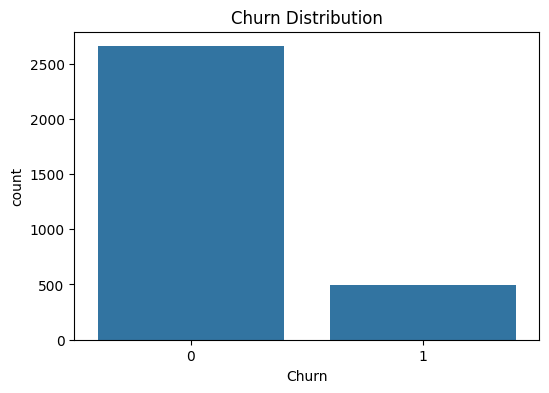

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Churn', data=df)
plt.title('Churn Distribution')
plt.show()

**DATA PREPROCESSING**

In [ ]:
df.drop(columns=['Age'], inplace=True, errors='ignore')
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
df.shape

(2850, 13)

In [ ]:
print("Current shape of df:", df.shape)
print("Remaining duplicate rows (all columns):", df.duplicated().sum())
# checking if there are duplicates when excluding the newly engineered features
print("Duplicate rows (excluding engineered features):", df.drop(columns=['seconds_per_call', 'sms_to_calls_ratio', 'charge_per_second', 'calls_per_sub_month'], errors='ignore').duplicated().sum())

Current shape of df: (2850, 13)
Remaining duplicate rows (all columns): 0
Duplicate rows (excluding engineered features): 0


In [ ]:
# Feature Engineering
eps = 1e-6
df['seconds_per_call'] = df['Seconds of Use'] / (df['Frequency of use'] + eps)
df['sms_to_calls_ratio'] = df['Frequency of SMS'] / (df['Frequency of use'] + eps)
df['charge_per_second'] = df['Charge Amount'] / (df['Seconds of Use'] + eps)
df['calls_per_sub_month'] = df['Frequency of use'] / (df['Subscription Length'] + eps)
df.fillna(0, inplace=True)
df.head()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Customer Value,Churn,seconds_per_call,sms_to_calls_ratio,charge_per_second,calls_per_sub_month
0,8,0,38,0,4370,71,5,17,3,1,1,197.640,0,61.549295,0.070423,0.0,1.868421
1,0,0,39,0,318,5,7,4,2,1,2,46.035,0,63.599987,1.400000,0.0,0.128205
2,10,0,37,0,2453,60,359,24,3,1,1,1536.520,0,40.883333,5.983333,0.0,1.621622
3,10,0,38,0,4198,66,1,35,1,1,1,240.020,0,63.606060,0.015152,0.0,1.736842
4,3,0,38,0,2393,58,2,33,1,1,1,145.805,0,41.258620,0.034483,0.0,1.526316


**HISTOGRAMS**

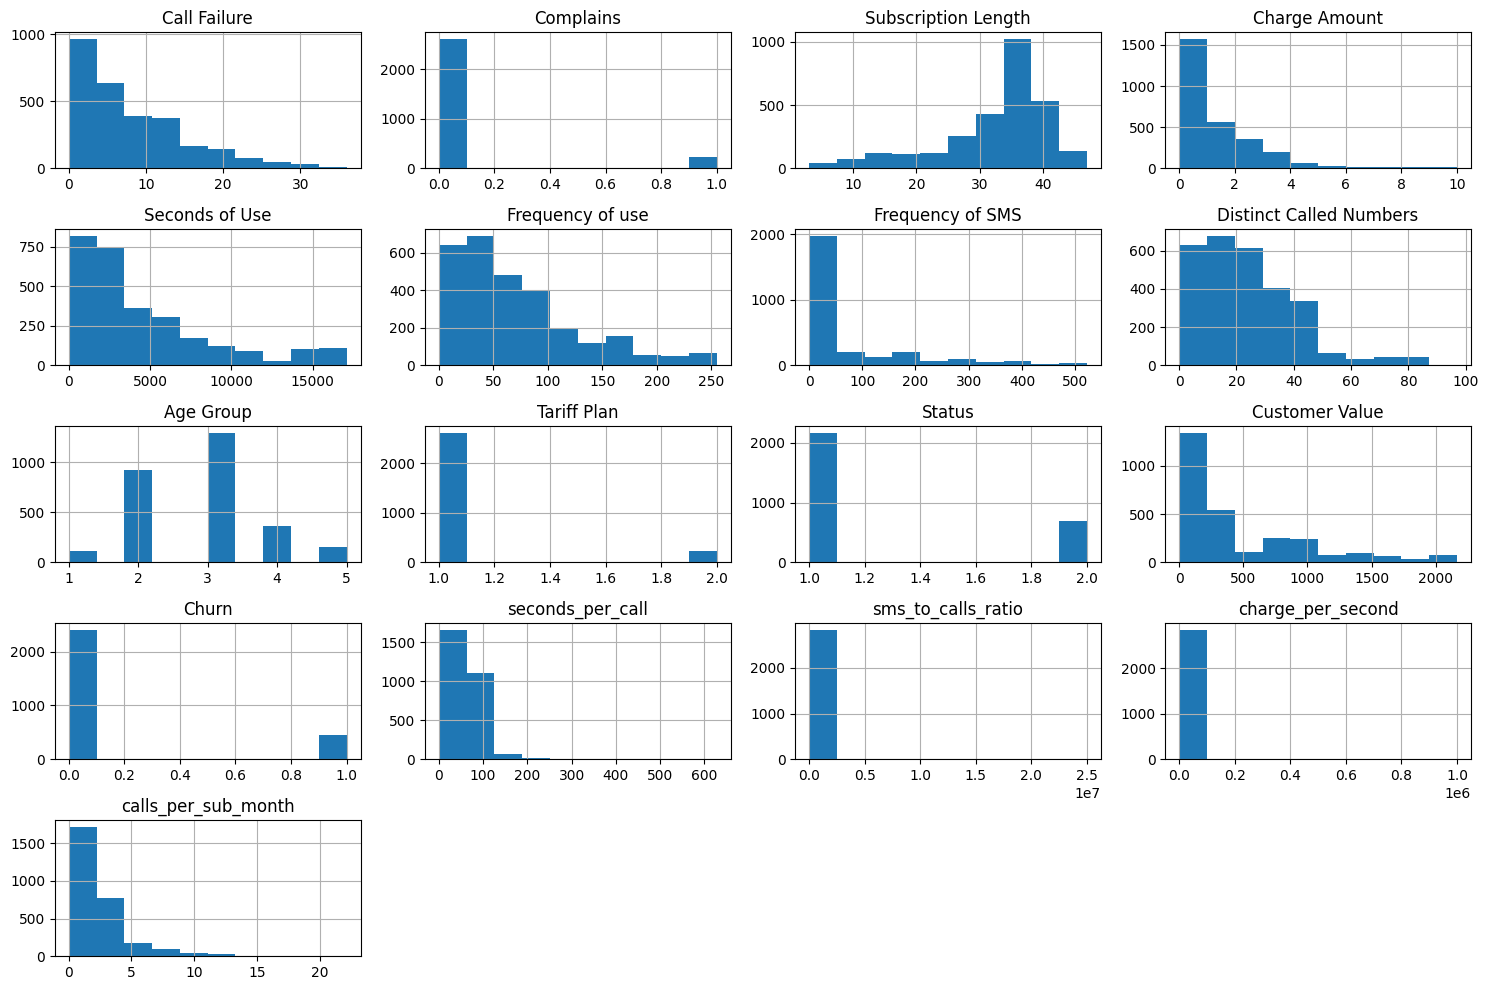

In [ ]:
numerical_features = df.select_dtypes(include=np.number).columns
df[numerical_features].hist(figsize=(15, 10))
plt.tight_layout()
plt.show()

**BOX PLOTS**

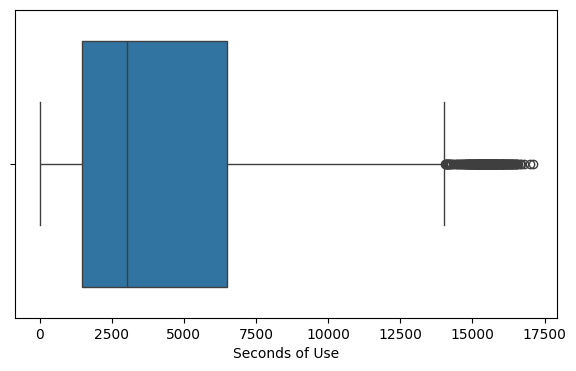

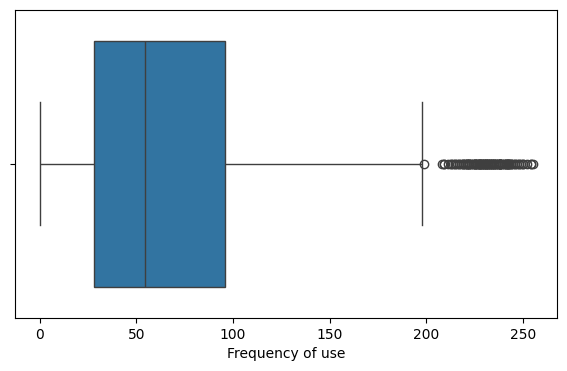

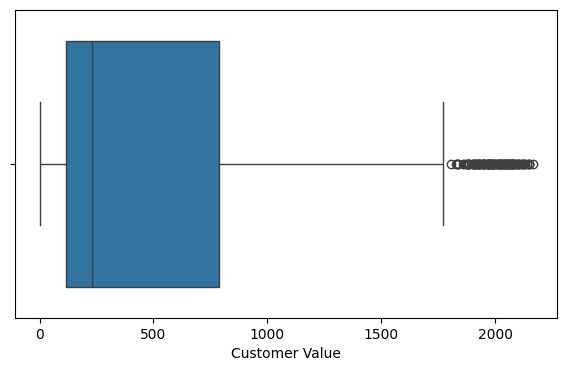

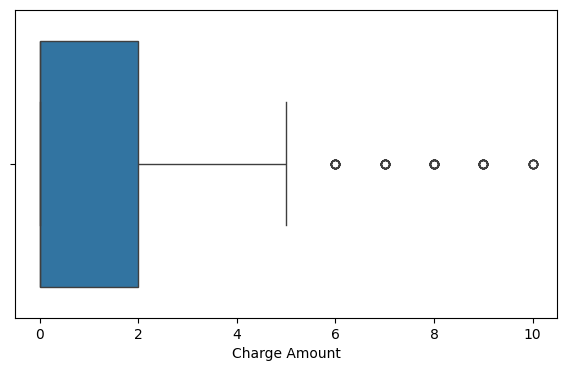

In [ ]:
for column in ['Seconds of Use', 'Frequency of use', 'Customer Value', 'Charge Amount']:
    plt.figure(figsize=(7, 4))
    sns.boxplot(x=df[column])
    plt.show()

Distribution of Usage: In telecom networks, a small percentage of customers (power users) consume a massive, disproportionate amount of data, call time, and SMS compared to the average subscriber.

**CORRELATION MATRIX**

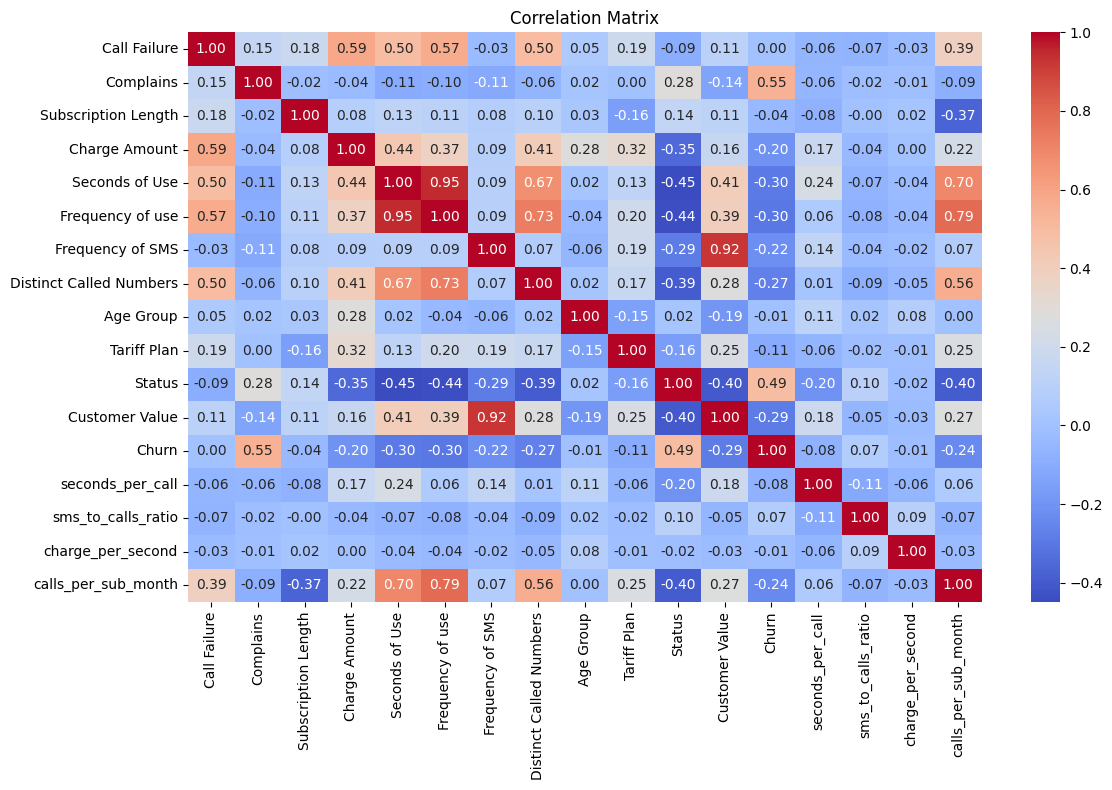

In [ ]:
correlation_matrix = df.corr()
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

**TRAIN TEST SPLIT AND SCALING**

In [ ]:
X = df.drop(columns=['Churn'])
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 2280
Testing samples: 570


In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_scaled = scaler.fit_transform(X)

**PCA - 2D VISUALISATION**
<br> mean of 0 and a standard deviation of 1

Variance explained by the 2 PCA components: 40.64 %


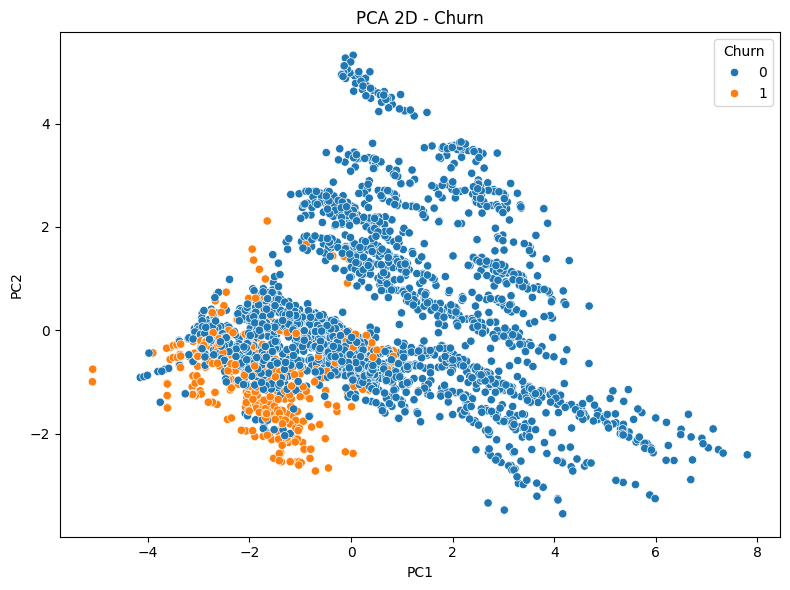

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print("Variance explained by the 2 PCA components:", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

plot_df = pd.DataFrame({"PC1": X_pca[:, 0], "PC2": X_pca[:, 1], "Churn": y.astype(str)})
plt.figure(figsize=(8, 6))
sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="Churn", palette="tab10")
plt.title("PCA 2D - Churn")
plt.tight_layout()
plt.show()

**FIND-S ALGORITHM**

In [ ]:
def find_s(X, y):
    hypothesis = None
    print("Initial Hypothesis:", hypothesis)

    for i in range(len(X)):
        if y[i] == 1 or y[i] == "Yes":
            if hypothesis is None:
                hypothesis = list(X[i])
            else:
                for j in range(len(hypothesis)):
                    if hypothesis[j] != X[i][j]:
                        hypothesis[j] = "?"

    return hypothesis

X_find_s = df[['Complains', 'Status', 'Tariff Plan']].values
y_find_s = df['Churn'].values
final_hypothesis = find_s(X_find_s, y_find_s)
print("\nFinal Hypothesis:")
print(final_hypothesis)

Initial Hypothesis: None

Final Hypothesis:
['?', '?', '?']


### Find - S is not suitable for this dataset
1. Inability to Handle Noise and Discrepancy

2. Ignoring Negative Examples

**Find-S relies on strict Boolean/symbolic equality (e.g., matching exact categories) and cannot evaluate continuous ranges, probabilistic likelihoods, or decision boundaries like Support Vector Machines or Naive Bayes do.**

**NAIVE BAYES CLASSIFIER**

Accuracy: 0.5666666666666667
Precision: 0.8776846883331645
Recall: 0.5666666666666667
F1-Score: 0.618499345334254

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.49      0.66       481
           1       0.26      0.98      0.41        89

    accuracy                           0.57       570
   macro avg       0.63      0.73      0.53       570
weighted avg       0.88      0.57      0.62       570



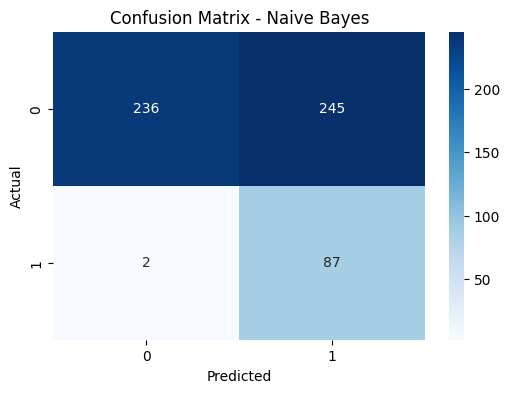

In [ ]:
gnb = GaussianNB()
gnb.fit(X_train_scaled, y_train)
y_pred_nb = gnb.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print("Precision:", precision_score(y_test, y_pred_nb, average='weighted', zero_division=0))
print("Recall:", recall_score(y_test, y_pred_nb, average='weighted', zero_division=0))
print("F1-Score:", f1_score(y_test, y_pred_nb, average='weighted', zero_division=0))
print("\nClassification Report:\n", classification_report(y_test, y_pred_nb, zero_division=0))

cm_nb = confusion_matrix(y_test, y_pred_nb)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix - Naive Bayes")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

**SUPPORT VECTOR MACHINE**

Linear SVM Accuracy: 0.9052631578947369
Linear SVM Precision: 0.8888888888888888
Linear SVM Recall: 0.449438202247191
Linear SVM F1 Score: 0.5970149253731343
              precision    recall  f1-score   support

           0       0.91      0.99      0.95       481
           1       0.89      0.45      0.60        89

    accuracy                           0.91       570
   macro avg       0.90      0.72      0.77       570
weighted avg       0.90      0.91      0.89       570



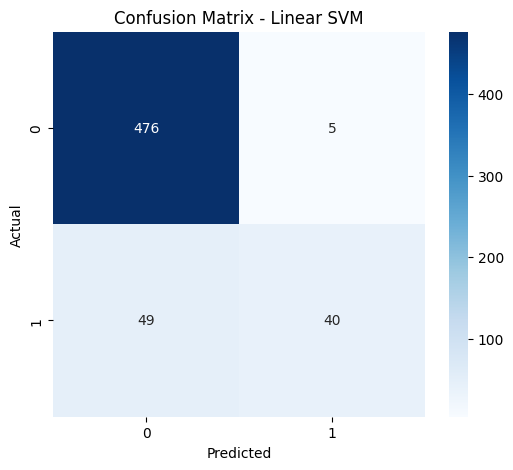

In [ ]:
linear_svm = SVC(kernel="linear")
linear_svm.fit(X_train_scaled, y_train)
y_pred_linear = linear_svm.predict(X_test_scaled)

accuracy_linear = accuracy_score(y_test, y_pred_linear)
precision_linear = precision_score(y_test, y_pred_linear, zero_division=0)
recall_linear = recall_score(y_test, y_pred_linear, zero_division=0)
f1_linear = f1_score(y_test, y_pred_linear, zero_division=0)

print("Linear SVM Accuracy:", accuracy_linear)
print("Linear SVM Precision:", precision_linear)
print("Linear SVM Recall:", recall_linear)
print("Linear SVM F1 Score:", f1_linear)
print(classification_report(y_test, y_pred_linear, zero_division=0))

cm_linear = confusion_matrix(y_test, y_pred_linear)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_linear, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Linear SVM")
plt.show()

RBF SVM Accuracy: 0.9210526315789473
RBF SVM Precision: 0.9230769230769231
RBF SVM Recall: 0.5393258426966292
RBF SVM F1 Score: 0.6808510638297872
              precision    recall  f1-score   support

           0       0.92      0.99      0.95       481
           1       0.92      0.54      0.68        89

    accuracy                           0.92       570
   macro avg       0.92      0.77      0.82       570
weighted avg       0.92      0.92      0.91       570



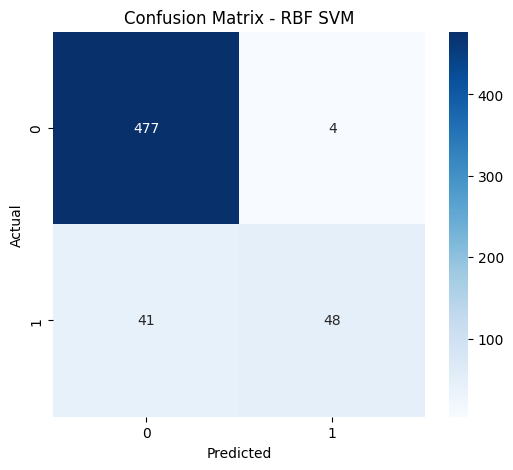

In [ ]:
rbf_svm = SVC(kernel="rbf")
rbf_svm.fit(X_train_scaled, y_train)
y_pred_rbf = rbf_svm.predict(X_test_scaled)

accuracy_rbf = accuracy_score(y_test, y_pred_rbf)
precision_rbf = precision_score(y_test, y_pred_rbf, zero_division=0)
recall_rbf = recall_score(y_test, y_pred_rbf, zero_division=0)
f1_rbf = f1_score(y_test, y_pred_rbf, zero_division=0)

print("RBF SVM Accuracy:", accuracy_rbf)
print("RBF SVM Precision:", precision_rbf)
print("RBF SVM Recall:", recall_rbf)
print("RBF SVM F1 Score:", f1_rbf)
print(classification_report(y_test, y_pred_rbf, zero_division=0))

cm_rbf = confusion_matrix(y_test, y_pred_rbf)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_rbf, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - RBF SVM")
plt.show()

**GRIDSEARCHCV - SVM TUNING**

In [ ]:
param_grid = [
    {
        'kernel': ['linear'],
        'C': [0.1, 1, 10]
    },
    {
        'kernel': ['rbf'],
        'gamma': [0.1, 1],
        'C': [0.1, 1, 10]
    }
]
grid_search = GridSearchCV(SVC(), param_grid, cv=3, scoring="f1", n_jobs=-1, verbose=1)
grid_search.fit(X_train_scaled, y_train)
print("GridSearch CV Completed")
print("Best parameters found:", grid_search.best_params_)
print("Best F1 Score:", grid_search.best_score_)

best_model = grid_search.best_estimator_
y_pred_tuned = best_model.predict(X_test_scaled)
accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
precision_tuned = precision_score(y_test, y_pred_tuned, zero_division=0)
recall_tuned = recall_score(y_test, y_pred_tuned, zero_division=0)
f1_tuned = f1_score(y_test, y_pred_tuned, zero_division=0)

print("Tuned SVM Accuracy:", accuracy_tuned)
print("Tuned SVM Precision:", precision_tuned)
print("Tuned SVM Recall:", recall_tuned)
print("Tuned SVM F1 Score:", f1_tuned)

Fitting 3 folds for each of 9 candidates, totalling 27 fits
GridSearch CV Completed
Best parameters found: {'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}
Best F1 Score: 0.8376301341070674
Tuned SVM Accuracy: 0.9491228070175438
Tuned SVM Precision: 0.8571428571428571
Tuned SVM Recall: 0.8089887640449438
Tuned SVM F1 Score: 0.8323699421965318


**MODEL COMPARISON**

,Model,Accuracy,Precision,Recall,F1 Score
0,Naive Bayes,0.566667,0.877685,0.566667,0.618499
1,Linear SVM,0.905263,0.888889,0.449438,0.597015
2,RBF SVM,0.921053,0.923077,0.539326,0.680851
3,Tuned SVM,0.949123,0.857143,0.808989,0.832370


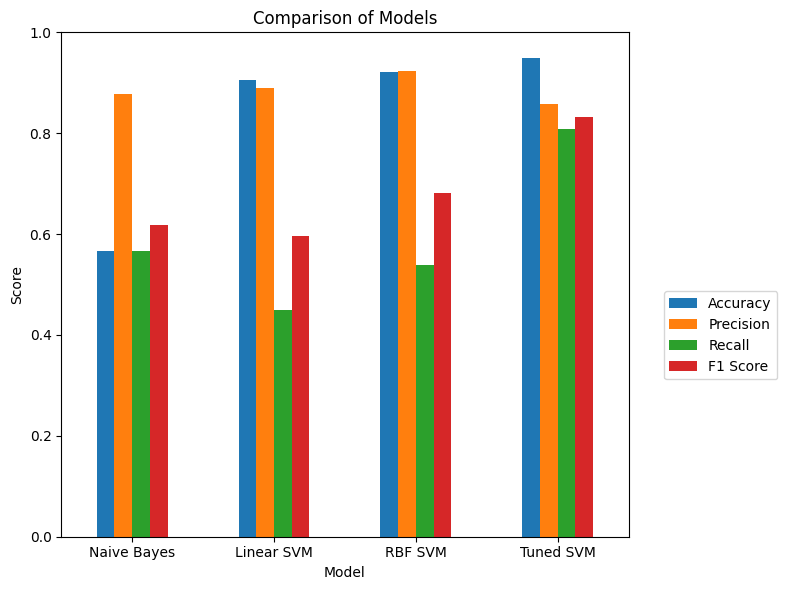

In [ ]:
final_comparison = pd.DataFrame({
    'Model': ['Naive Bayes', 'Linear SVM', 'RBF SVM', 'Tuned SVM'],
    'Accuracy': [accuracy_score(y_test, y_pred_nb), accuracy_linear, accuracy_rbf, accuracy_tuned],
    'Precision': [precision_score(y_test, y_pred_nb, average='weighted', zero_division=0), precision_linear, precision_rbf, precision_tuned],
    'Recall': [recall_score(y_test, y_pred_nb, average='weighted', zero_division=0), recall_linear, recall_rbf, recall_tuned],
    'F1 Score': [f1_score(y_test, y_pred_nb, average='weighted', zero_division=0), f1_linear, f1_rbf, f1_tuned]
})
display(final_comparison)

final_comparison.set_index('Model').plot(kind='bar', figsize=(8, 6))
plt.title('Comparison of Models')
plt.xlabel('Model')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.05, 0.5), loc='upper left')
plt.tight_layout()
plt.show()

### Comparing Train-Test Split Ratios

,Split Ratio (Train/Test),Train Size,Test Size,Accuracy,Precision,Recall,F1 Score
0,90/10,2565,285,0.912281,0.884615,0.511111,0.647887
1,80/20,2280,570,0.921053,0.923077,0.539326,0.680851
2,75/25,2137,713,0.924264,0.939394,0.553571,0.696629
3,70/30,1995,855,0.916959,0.931507,0.507463,0.657005
4,60/40,1710,1140,0.909649,0.912088,0.466292,0.617100


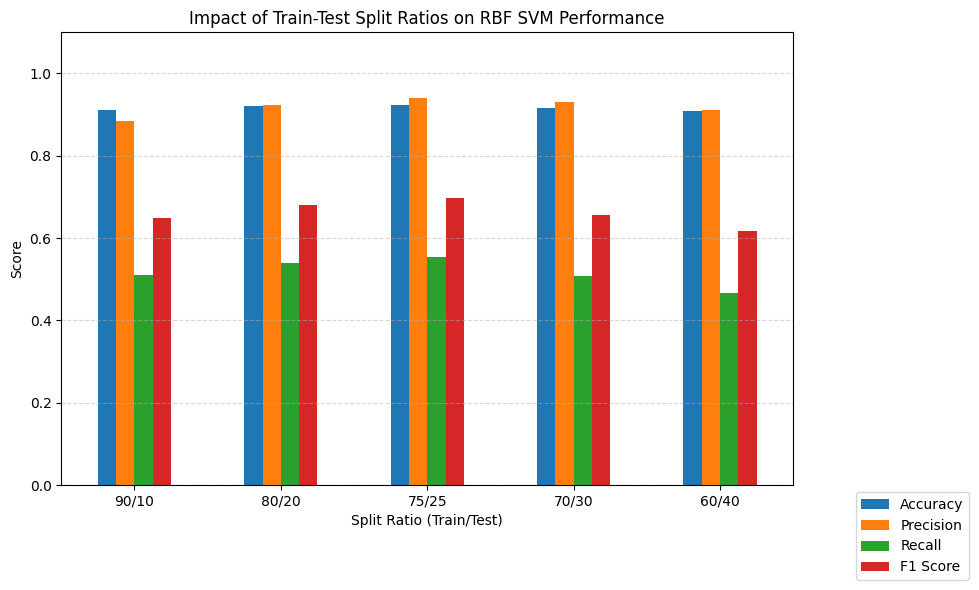

In [ ]:
# Define split ratios to test (e.g., 90/10, 80/20, 70/30, 60/40)
split_ratios = {
    '90/10': 0.10,
    '80/20': 0.20,
    '75/25': 0.25,
    '70/30': 0.30,
    '60/40': 0.40
}

results = []

# Prepare features
X_data = df.drop(columns=['Churn'])
y_data = df['Churn']

for name, test_size in split_ratios.items():
    # Split
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_data, y_data, test_size=test_size, random_state=42, stratify=y_data
    )

    # Scale
    sc = StandardScaler()
    X_tr_sc = sc.fit_transform(X_tr)
    X_te_sc = sc.transform(X_te)

    # Train RBF SVM
    clf = SVC(kernel='rbf')
    clf.fit(X_tr_sc, y_tr)
    y_pred = clf.predict(X_te_sc)

    # Calculate metrics
    results.append({
        'Split Ratio (Train/Test)': name,
        'Train Size': X_tr.shape[0],
        'Test Size': X_te.shape[0],
        'Accuracy': accuracy_score(y_te, y_pred),
        'Precision': precision_score(y_te, y_pred, zero_division=0),
        'Recall': recall_score(y_te, y_pred, zero_division=0),
        'F1 Score': f1_score(y_te, y_pred, zero_division=0)
    })

# Display DataFrame
split_comparison_df = pd.DataFrame(results)
display(split_comparison_df)

# Plot results
split_comparison_df.set_index('Split Ratio (Train/Test)')[['Accuracy', 'Precision', 'Recall', 'F1 Score']].plot(kind='bar', figsize=(10, 6))
plt.title('Impact of Train-Test Split Ratios on RBF SVM Performance')
plt.ylabel('Score')
plt.xlabel('Split Ratio (Train/Test)')
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor = (1.25,0))
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**SKLEARN PIPELINE WITH COLUMNTRANSFORMER**

In [ ]:
categorical_features = ['Status', 'Tariff Plan', 'Complains']
numerical_features = [col for col in X.columns if col not in categorical_features]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(kernel="rbf"))
    ]
)
pipeline.fit(X_train, y_train)
y_pred_pipe = pipeline.predict(X_test)
print("Pipeline Accuracy:", accuracy_score(y_test, y_pred_pipe))
print("Pipeline F1 Score:", f1_score(y_test, y_pred_pipe, zero_division=0))
print(classification_report(y_test, y_pred_pipe, zero_division=0))

Pipeline Accuracy: 0.9192982456140351
Pipeline F1 Score: 0.6666666666666666
              precision    recall  f1-score   support

           0       0.92      0.99      0.95       481
           1       0.94      0.52      0.67        89

    accuracy                           0.92       570
   macro avg       0.93      0.76      0.81       570
weighted avg       0.92      0.92      0.91       570



**REGRESSION - PREDICT CUSTOMER VALUE**

In [ ]:
y_reg = df['Customer Value']
X_reg = df.drop(columns=['Customer Value', 'Churn'])

Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

# Linear Regression
mlr = LinearRegression()
mlr.fit(Xr_train, yr_train)
mlr_pred = mlr.predict(Xr_test)
print("Linear Regression:")
print("MAE: ", mean_absolute_error(yr_test, mlr_pred))
print("MSE: ", mean_squared_error(yr_test, mlr_pred))
print("RMSE: ", np.sqrt(mean_squared_error(yr_test, mlr_pred)))
print("R2: ", r2_score(yr_test, mlr_pred))

# Ridge Regression
ridge = Ridge()
ridge.fit(Xr_train, yr_train)
ridge_pred = ridge.predict(Xr_test)
print("\nRidge Regression:")
print("MAE: ", mean_absolute_error(yr_test, ridge_pred))
print("MSE: ", mean_squared_error(yr_test, ridge_pred))
print("RMSE: ", np.sqrt(mean_squared_error(yr_test, ridge_pred)))
print("R2: ", r2_score(yr_test, ridge_pred))

# Lasso Regression
lasso = Lasso(max_iter=5000)
lasso.fit(Xr_train, yr_train)
lasso_pred = lasso.predict(Xr_test)
print("\nLasso Regression:")
print("MAE: ", mean_absolute_error(yr_test, lasso_pred))
print("MSE: ", mean_squared_error(yr_test, lasso_pred))
print("RMSE: ", np.sqrt(mean_squared_error(yr_test, lasso_pred)))
print("R2: ", r2_score(yr_test, lasso_pred))

Linear Regression:
MAE:  45.23915446466884
MSE:  5842.681519979149
RMSE:  76.43743533098916
R2:  0.9773946073334339

Ridge Regression:
MAE:  45.218038351024106
MSE:  5843.017848430818
RMSE:  76.43963532376917
R2:  0.9773933060753234

Lasso Regression:
MAE:  44.6841198973925
MSE:  5879.923609697064
RMSE:  76.68065994562816
R2:  0.9772505173194705


**CLUSTERING - KMEANS**

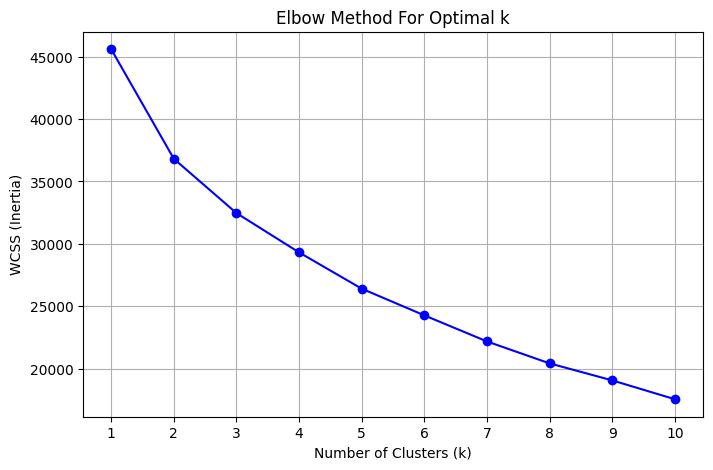

In [ ]:
wcss = []
cluster_range = range(1, 11)

for k in cluster_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(cluster_range, wcss, marker='o', linestyle='-', color='b')
plt.title('Elbow Method For Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(cluster_range)
plt.grid(True)
plt.show()

In [ ]:
silhouette_scores = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)
    print(f"For n_clusters = {k}, the average silhouette_score is : {score:.4f}")

silhouette_table = pd.DataFrame({'n_clusters': k_range, 'silhouette_score': silhouette_scores})
display(silhouette_table)

For n_clusters = 2, the average silhouette_score is : 0.2379
For n_clusters = 3, the average silhouette_score is : 0.2317
For n_clusters = 4, the average silhouette_score is : 0.2112
For n_clusters = 5, the average silhouette_score is : 0.2127
For n_clusters = 6, the average silhouette_score is : 0.2292
For n_clusters = 7, the average silhouette_score is : 0.2533
For n_clusters = 8, the average silhouette_score is : 0.2520
For n_clusters = 9, the average silhouette_score is : 0.2541
For n_clusters = 10, the average silhouette_score is : 0.2717


,n_clusters,silhouette_score
0,2,0.237907
1,3,0.231740
2,4,0.211170
3,5,0.212690
4,6,0.229195
5,7,0.253288
6,8,0.251960
7,9,0.254104
8,10,0.271695


In [ ]:
suggested_k = int(
    silhouette_table.loc[silhouette_table['silhouette_score'].idxmax(), 'n_clusters']
)
print("K suggested by the highest silhouette score", suggested_k)

K = suggested_k
kmeans_model = KMeans(n_clusters=K, random_state=42, n_init=10)
kmeans_labels = kmeans_model.fit_predict(X_scaled)

df_kmeans = df.copy()
df_kmeans["KMeans_Cluster"] = kmeans_labels
print("K-Means Clustering Completed.")
print("\nNumber of customers in each cluster: ")
print(df_kmeans["KMeans_Cluster"].value_counts().sort_index())

K suggested by the highest silhouette score 10
K-Means Clustering Completed.

Number of customers in each cluster: 
KMeans_Cluster
0    299
1    911
2    392
3      3
4    542
5    189
6      2
7    259
8     61
9    192
Name: count, dtype: int64


In [ ]:
print("Minimum Customer Value:", df['Customer Value'].min())
print("Maximum Customer Value:", df['Customer Value'].max())

Minimum Customer Value: 0.0
Maximum Customer Value: 2165.28
